# Fine-Tuning Genomic LLMs

---

## Learning Outcomes

By the end of this session, participants will be able to:
- fine-tune a pretrained genomic transformer with the Hugging Face `Trainer` API
- set up `TrainingArguments`, including early stopping and checkpointing
- save, reload, and run inference with a fine-tuned model
- evaluate a fine-tuned sequence classifier

## credits

This notebook is adapted from [Meg Hedge's ECCB2026 tutorial](https://github.com/meghegde/genomic-llms-in-practice/tree/main).

In this notebook, we take a pretrained DNA language model and adapt it to a downstream classification task — promoter vs. non-promoter — instead of using it off-the-shelf as we did with ESM-2 in the previous session. We rely on the Hugging Face `Trainer` API to handle the training loop, and we finish with *in silico* saturated mutagenesis to interrogate what the model has learned.

We use [DNABERT (6-mer)](https://huggingface.co/zhihan1996/DNA_bert_6), which tokenizes DNA into overlapping 6-mers (as in the first session) and was pretrained with masked-token prediction (as in the second). Unlike the previous notebooks, this session requires a GPU (a T4 on Colab or Kaggle is enough).


## Install and import required packages

In [1]:
# Installing required libraries
!pip -q install transformers datasets evaluate accelerate scikit-learn seaborn matplotlib


In [2]:
# Importing required libraries
import numpy as np
import pandas as pd
import torch

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

from sklearn.metrics import accuracy_score, f1_score


In [3]:
# checking available device
device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device")

Using cuda device


## Why fine-tune?

In the previous sessions we used pretrained models **off-the-shelf**. Fine-tuning goes one step further: we keep everything the model learned during pre-training and adapt it to a specific task using a small labelled dataset — transfer learning.

![](../images/dallatorre2023_fig1.png)

Figure 1 c. & d. from [Dalla-Torre et al.](https://www.biorxiv.org/content/10.1101/2023.01.11.523679v2)

What we have done in notebook 02 correspond to the top sub-figure, where we keep the LLM unchanged and train a classifier on its embedding.

What we are going to do in this notebook corresponds to the bottom part, where we adjust the weights of the whole model to make them more suitable to our purpose.


---

For genomic sequence classification this typically beats the two obvious alternatives:

- **Classical ML** (random forests or SVMs on handcrafted features, e.g. GC-content or k-mer counts) discards the spatial arrangement of the sequence.
- **Training from scratch** requires far more labelled data and compute than any downstream task can provide.

Because attention (nb02) already encodes the regulatory context of each 6-mer (tokenized as in nb01), fine-tuning mostly redirects this knowledge through a small classification head.



## The Model: DNABERT (6-mer)

We fine-tune [`zhihan1996/DNA_bert_6`](https://huggingface.co/zhihan1996/DNA_bert_6), the 6-mer checkpoint of **DNABERT** ([Ji et al., 2021](https://doi.org/10.1093/bioinformatics/btab083); [code](https://github.com/jerryji1993/DNABERT); [huggingface](huggingface.co/zhihan1996/DNA_bert_6)):

- **Architecture**: a BERT-base-sized bidirectional Transformer — 12 layers, 12 attention heads, hidden size 768 (~90M parameters). The same masked-token pre-training recipe we used with ESM-2 in notebook 02, applied to DNA.
- **Pre-training corpus**: the human genome (GRCh38) — no task labels involved, only masked 6-mer prediction
- **Vocabulary**: the 4^6 = 4,096 possible 6-mers plus 5 special tokens (vocab size 4,101); the sliding-window tokenization below yields ~1 token per nucleotide position
- **Context size**: 512 k-mer tokens ~ 510 bp of DNA

The original paper already shows where this is going: this model family reached state-of-the-art promoter prediction "after easy fine-tuning using small task-specific labeled data".

In [4]:
MODEL_NAME = "zhihan1996/DNA_bert_6"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

config.json:   0%|          | 0.00/1.45k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/40.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/28.7k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

## The Task: Promoter Classification

Promoters are short regulatory regions at the start of genes: they tell the transcription machinery where to bind and from which nucleotide to begin reading the gene. Predicting them from sequence alone is a classic binary classification problem — given a window of DNA, is it a promoter or genomic background?

### Dataset

We use the `NT_promoter_all` configuration of the Genomic Benchmarks collection on Hugging Face: [datasets/darlednik/geneb-tasks](https://huggingface.co/datasets/darlednik/geneb-tasks)

- **300 bp human DNA windows**, centered on annotated transcription start sites for positives versus random genomic background for negatives — comfortably sits below the maximum model context size of 510bp

- **53,276 train / 5,920 test** sequences; label `1` = promoter, `0` = non-promoter
- from the Nucleotide Transformer benchmark suite ([Dalla-Torre et al., 2023](https://www.biorxiv.org/content/10.1101/2023.01.11.523679v2)) — the same paper as the figure above
- the repository aggregates ~100 benchmark configs (`NT_*`, `GB_*`, `GUE_*`, ...): splice sites, enhancers, histone marks, ... — a ready-made playground if you want to fine-tune on a second task

In [5]:
# Loading dataset
promoter_dataset = load_dataset("darlednik/geneb-tasks", "NT_promoter_all")
promoter_dataset

promoter_dataset["train"][0]

README.md:   0%|          | 0.00/24.3k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/100 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/100 [00:00<?, ?it/s]

tasks/InstaDeepAI_nucleotide_transformer(…): reconstructing file:   0%|          |  0.00B / 16.2MB            

tasks/InstaDeepAI_nucleotide_transformer(…): downloading bytes:           |  0.00B            

test.csv:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/53276 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5920 [00:00<?, ? examples/s]

{'text': 'ATAAAGCAACAGGAGGACACCGGCTCTCGCGTCATTAGGTCACACAATGTCTCAGTTTAAGGCGGGTGGGGTGGGCCAGACTCACAGCTGAGATAGAATTATTGCGAGATAACTCTGTTTAAGTAGCTAGGCTTGAAAATGGACGGTGAGTACCCTAGGACGTGCCCCAGGGCCAGTGGGATAAAGGTACACGCCGGCGGGGGCATGAGTCAGGGGTTTGCGAGCGAAAAAAGGAGCATTGGTTGCTACTGCGTTAGTGGGAACGTAGCTGGTCGCAGAGGGCACCTAATGCTGGCACCC',
 'label': 0}

### Tokenization

#### Inside the Genomic Tokenizer

DNABERT_6 represents the DNA sequences using an **overlapping sliding window** of 6-mers (k-mers of length 6).

The reasonning behind this is that because biological signals don't have spaces or punctuation. Overlapping k-mers preserve the continuous spatial context of the sequence, ensuring no biological motif is accidentally split across a token boundary.

A 300 bp sequence therefore yields 295 overlapping 6-mers: we set `max_length=300` below so the full window fits inside the model's 512-position context with no truncation.


In [6]:
# Visualize the Sliding Window K-mer Extraction
def visualize_kmer_tokenization(sequence, k=6):
    print(f"Raw Sequence: {sequence}\n")
    print(f"Extracted {k}-mers (Sliding Window):")

    kmers = [sequence[i:i+k] for i in range(len(sequence) - k + 1)]
    for i, kmer in enumerate(kmers):
        # Indent to show the overlap visually
        print(f"{' ' * i}{kmer}")

# Testing on a short 15-base sequence
sample_dna = "ATGCGTAACGTTGAC"
visualize_kmer_tokenization(sample_dna)


Raw Sequence: ATGCGTAACGTTGAC

Extracted 6-mers (Sliding Window):
ATGCGT
 TGCGTA
  GCGTAA
   CGTAAC
    GTAACG
     TAACGT
      AACGTT
       ACGTTG
        CGTTGA
         GTTGAC


In [7]:
# Function to generate overlapping k-mers from a given sequence
def seq2kmer(seq, k=6):
    return " ".join([seq[i:i+k] for i in range(len(seq) - k + 1)])

# Function to tokenize a given sequence
def tokenize_promoter(example):
    # Convert a batch of raw strings to spaced k-mers
    kmer_texts = [seq2kmer(seq) for seq in example["text"]]

    return tokenizer(
        kmer_texts,
        truncation=True,
        padding="max_length",
        max_length=300
    )


tokenized_promoter = promoter_dataset.map(tokenize_promoter, batched=True)


Map:   0%|          | 0/53276 [00:00<?, ? examples/s]

Map:   0%|          | 0/5920 [00:00<?, ? examples/s]

In [23]:
# We will subset the data in the interest of time

# Train/Test dataset with 80-20 split
train_promoter = tokenized_promoter["train"].shuffle(seed=42).select(range(8000))
valid_promoter = tokenized_promoter["test"].shuffle(seed=42).select(range(1000))



In [24]:
pd.Series( train_promoter['label'] ).value_counts()




,count
1,4013
0,3987


## Fine-tuning


### Evaluation Metrics

We use:
- Accuracy
- F1-score

F1-score is especially important in genomics due to:
- **imbalance**: categories of interest are often massively under-represented
- **asymmetric biological consequences**: we generally consider that False Positives are not equivalent to False Negatives (ie, they have different biological meaning and consequences)
- **sensitivity/precision requirements**: despite imbalance we want to control FDR (precision) while being as sensitive as possible.

> **NB:** F1 is mostly appropriate for binary classification. If you have multiclass data, balanced accuracy will often be more appropriate than the different flavors of aggregated F1 scores.

In [9]:
# Function to compute evaluation metrics
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)

    f1 = f1_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "f1": f1
    }


### Loading the pretrained model for a new classification task

We use [AutoModelForSequenceClassification](https://huggingface.co/transformers/v3.0.2/model_doc/auto.html#automodelforsequenceclassification) which allow us to load a pretrained model and change the orginial head with a new MLP classifier.

> more on AutoModelForSequenceClassification in this [medium article](https://medium.com/learning-data/under-the-hood-of-automodelforsequenceclassification-in-hugging-face-transformers-e497bc78d828)

In [10]:
promoter_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  359MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  359MB            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

[transformers] BertForSequenceClassification LOAD REPORT from: zhihan1996/DNA_bert_6
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Let's take a look at the model:

In [11]:
promoter_model

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(4101, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, 

In [12]:
## looking at the classifier head
promoter_model.classifier

Linear(in_features=768, out_features=2, bias=True)

In [13]:
## counting the number of trainable parameter
trainable_params = sum(p.numel() for p in promoter_model.parameters() if p.requires_grad)
print( f"number of trainable parameters: {trainable_params:,}")

number of trainable parameters: 89,192,450


### Determining batch size - GPU memory

Batch size is not a free choice - it is capped by GPU memory. Peak memory during full fine-tuning has two parts:

- **Static cost** (independent of batch size): fp32 training spends ~16 bytes per parameter ( weights (4) + gradients (4) + the two AdamW states (2 × 4) ). For ~90M parameters that is ~1.4 GB, plus ~0.5 GB for the CUDA context and cuDNN kernels. This bill is identical for a batch of 1 or 64.
- **Dynamic cost** (saved activations, needed for backpropagation): it grows *linearly with the batch size*, and with *sequence length* it grows superlinearly — the attention term scales as `batch × heads × s²`.

Rather than trusting a hand-derived formula, **probe and extrapolate**: peak memory as a function of batch size `b` is a straight line,

```
peak(b) = static + slope × b        →   safe_max_batch ≈ 0.8 × (GPU_total − static) / slope
```

so two measurements are enough to fit it; the ~20% margin absorbs allocator fragmentation. The cell below fits the line on your machine's GPU — it costs two mini training steps and returns the model to the CPU afterwards:

In [14]:
# Empirical batch-size probe: peak memory (fwd + bwd + one AdamW step) at two batch sizes
def probe_batch_memory(model, batch_size, seq_len=300, vocab_size=4101):
    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    input_ids = torch.randint(5, vocab_size, (batch_size, seq_len), device="cuda")
    attention_mask = torch.ones_like(input_ids)
    labels = torch.randint(0, 2, (batch_size,), device="cuda")

    output = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
    output.loss.backward()
    optimizer.step()
    peak_gb = torch.cuda.max_memory_allocated() / 1e9

    del optimizer, output, input_ids, attention_mask, labels
    torch.cuda.empty_cache()
    return peak_gb

if torch.cuda.is_available():
    b1, b2 = 4, 16
    m1 = probe_batch_memory(promoter_model.cuda(), b1)
    m2 = probe_batch_memory(promoter_model, b2)
    promoter_model.cpu()

    slope = (m2 - m1) / (b2 - b1)      # GB added by each extra sequence in the batch
    static = m1 - slope * b1           # weights + gradients + AdamW states + CUDA context
    gpu_total = torch.cuda.get_device_properties(0).total_memory / 1e9
    max_batch = int(0.8 * (gpu_total - static) / slope)

    print(f"GPU total:   {gpu_total:.1f} GB")
    print(f"Static cost: {static:.2f} GB")
    print(f"Per sample:  {slope:.3f} GB (at 300 tokens per sequence)")
    print(f"Safe max batch (80% budget): {max_batch}")
else:
    print("No GPU detected — the probe needs CUDA.")
    print("Expect on a 16 GB GPU: static ~2-2.5 GB, ~0.1-0.2 GB per sample at 300 tokens,")
    print("i.e. a safe batch of roughly 32-64 for this 90M-parameter model.")

GPU total:   15.6 GB
Static cost: 1.16 GB
Per sample:  0.164 GB (at 300 tokens per sequence)
Safe max batch (80% budget): 70


### Setting up the Trainer

`TrainingArguments` configures the training loop executed by the `Trainer`. Every argument used in the next cell:

- `output_dir` : folder where checkpoints, logs and configs are written
- `eval_strategy="epoch"` / `save_strategy="epoch"` : evaluate on the test split and save a checkpoint at the end of each epoch; identical strategies are required for the best-model tracking below
- `learning_rate=3e-5` : generally 10-100x lower than pre-training rates (the classic BERT band is 1e-5 to 5e-5). Large enough to adapt the features, small enough not to erase the pre-trained knowledge (catastrophic forgetting)
- `per_device_train_batch_size=64` : see previous subsection
- `num_train_epochs=3` — the weights are already pre-trained: one pass over the 20k training sequences is enough to reshape the head and the features
- `weight_decay=0.01` — AdamW's decoupled L2 regularization: penalizes large weights to limit overfitting
- `logging_steps=10` — log the training loss every 10 steps so we can watch it decrease


**Model selection.** The *last* checkpoint of a fine-tuning run is not necessarily the best — validation scores typically peak, then decay as the model starts to overfit:

- `load_best_model_at_end=True` + `metric_for_best_model="f1"` — reload the checkpoint with the best validation F1 at the end of training
- `EarlyStoppingCallback(early_stopping_patience=1)` — stop training when validation F1 stops improving for one epoch. This is a `Trainer` **callback**, not a `TrainingArguments` setting

Both monitor the validation metric — the safety net against overfitting that raw training loss cannot provide.

---

One important element we do not touch here is the **loss** function. As it is used to compute the gradients which will optimize the weight, it is a crucial element.

The default for 2 categories is the binary cross-entropy, which a classical and fine choice **when the class are balanced** (which is the case here).

When the class are unbalanced it is useful to use a custom loss function which accounts for it (eg, by reweighting the samples to the inverse of their frequency).
We will not do it here, but you can look up this
[example (with a focal loss)](https://discuss.huggingface.co/t/create-a-weighted-loss-function-to-handle-imbalance/138178/3#p-199274-h-2-implement-your-custom-loss-function-2), and the [`compute_loss_func` argument of `Trainer`](https://huggingface.co/docs/transformers/en/main_classes/trainer#transformers.Trainer.compute_loss_func)



In [25]:
promoter_training_args = TrainingArguments(
    output_dir="./promoter_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=64,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="f1"
)

promoter_trainer = Trainer(
    model=promoter_model,
    args=promoter_training_args,
    train_dataset=train_promoter,
    eval_dataset=valid_promoter,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

### Actually fine-tuning the Model

The following cell will take several minutes to run (~8min per epoch in my test)

In [26]:

promoter_trainer.train()

promoter_results = promoter_trainer.evaluate()
promoter_results

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.153663,0.142213,0.945000,0.944945
2,0.108834,0.134380,0.949000,0.949555
3,0.114127,0.133522,0.952000,0.952191


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1
0.114127,0.133522,3,0.952000,0.952191


{'eval_loss': 0.13352185487747192,
 'eval_accuracy': 0.952,
 'eval_f1': 0.952191235059761}

### Saving and Reloading the Model

important for:
- reproducibility
- downstream inference
- sharing checkpoints


In [27]:
# Saving the fine-tuned model
promoter_trainer.save_model("./promoter_model")
tokenizer.save_pretrained("./promoter_model")

# Loading the saved model back
loaded_promoter_model = AutoModelForSequenceClassification.from_pretrained(
    "./promoter_model"
)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

## Further Reading

Fine-tuning is a subject on which much more time could be spent.
If you want to dig deeper, here is 3 nice guides:

* https://lalatenduswain.medium.com/fine-tuning-pre-trained-models-the-right-way-a-step-by-step-guide-to-learning-rate-strategy-b3d9c0307222
* https://blog.neosage.io/p/an-engineers-guide-to-fine-tuning-cd5
* https://latitude.so/blog/fine-tuning-llms-hyperparameter-best-practices

You will see some advice there that we have not followed in this simple frist-example, but which we discuss in the annexes.

## Inference on the fine-tuned model

We now perform prediction on unseen sequences.


In [28]:
# Method to perform prediction on a sequence using the fine-tuned model
def promoter_predict(sequence):

    inputs = tokenizer(
        sequence,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=300
    )

    with torch.no_grad():
        outputs = loaded_promoter_model(**inputs)

    prediction = torch.argmax(outputs.logits, dim=1).item()
    return prediction


In [29]:
# Run prediction
sample_sequence = promoter_dataset["test"][4000]["text"]

prediction = promoter_predict(sample_sequence)

print("Predicted label:", prediction)
print("Actual label:", promoter_dataset["test"][4000]["label"])


Predicted label: 1
Actual label: 1


## Probing the Representations: Before vs After Fine-Tuning

The classifier head tells us *that* fine-tuning worked — not *where inside the network* promoter information lives, or what the pre-trained model already knew.

**Probing** answers this: freeze the hidden states of each layer, train a tiny logistic regression on top of those frozen embeddings, and read its accuracy. A probe measures how *linearly accessible* the task information is at a given depth, without touching the model itself.

We compare two conditions on the *same* sequences:

- **Base**: fresh `zhihan1996/DNA_bert_6` from the hub — what the pre-trained features alone can support
- **Fine-tuned**: the model we just saved

And instead of a single lucky train/test split we run **5-fold stratified cross-validation** per layer, reporting mean ± std. (Further reading: [Hewitt & Liang, Designing and Interpreting Probes with Control Tasks](https://arxiv.org/abs/1905.05950).)

In [38]:
%%time
# Extract pooled embeddings for every layer of a model, on the same sequences for both conditions
PROBE_SIZE = 250

device = "cuda" if torch.cuda.is_available() else "cpu"

def get_layerwise_embeddings(model, sequences, batch_size=64):
    # Returns a list of (num_layers + 1) arrays of shape (n_sequences, hidden_size):
    # index 0 = input embedding layer, 1..12 = transformer layers
    model.eval().to(device)
    per_layer = None

    for start in range(0, len(sequences), batch_size):
        batch_texts = [seq2kmer(seq) for seq in sequences[start:start + batch_size]]
        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            truncation=True,
            padding="max_length",
            max_length=300,
        ).to(device)

        with torch.no_grad():
            outputs = model(**inputs, output_hidden_states=True)

        mask = inputs["attention_mask"].unsqueeze(-1)  # (batch, seq_len, 1)
        if per_layer is None:
            per_layer = [[] for _ in outputs.hidden_states]

        # Attention-mask-aware mean pooling over real (non-padding) tokens
        for layer_idx, hidden in enumerate(outputs.hidden_states):
            summed = (hidden * mask).sum(dim=1)
            counts = mask.sum(dim=1).clamp(min=1)
            per_layer[layer_idx].append((summed / counts).cpu().numpy())

    model.cpu()
    if device == "cuda":
        torch.cuda.empty_cache()
    return [np.concatenate(chunks, axis=0) for chunks in per_layer]


probe_dataset = tokenized_promoter["test"].shuffle().select(range(PROBE_SIZE))
probe_sequences = probe_dataset["text"]
probe_labels = np.array(probe_dataset["label"])

base_probe_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2
)

probe_embeddings = {
    "Base": get_layerwise_embeddings(base_probe_model, probe_sequences),
    "Fine-tuned": get_layerwise_embeddings(loaded_promoter_model, probe_sequences),
}
del base_probe_model

n_layers = len(probe_embeddings["Base"])
print(f"Layers per model (incl. input embeddings): {n_layers}")
print(f"Embedding shape: {probe_embeddings['Base'][0].shape}")
print(f"Probed sequences: {len(probe_sequences)}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: zhihan1996/DNA_bert_6
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Layers per model (incl. input embeddings): 13
Embedding shape: (250, 768)
Probed sequences: 250
CPU times: user 8.03 s, sys: 424 ms, total: 8.45 s
Wall time: 13.5 s


           Layer |          Base |    Fine-tuned
Input embeddings |   0.848 ±0.052 |   0.848 ±0.052
         Layer 1 |   0.900 ±0.022 |   0.904 ±0.023
         Layer 2 |   0.884 ±0.039 |   0.888 ±0.043
         Layer 3 |   0.888 ±0.041 |   0.896 ±0.034
         Layer 4 |   0.888 ±0.057 |   0.912 ±0.045
         Layer 5 |   0.912 ±0.041 |   0.928 ±0.020
         Layer 6 |   0.896 ±0.032 |   0.920 ±0.033
         Layer 7 |   0.904 ±0.015 |   0.936 ±0.029
         Layer 8 |   0.880 ±0.042 |   0.916 ±0.034
         Layer 9 |   0.900 ±0.025 |   0.928 ±0.035
        Layer 10 |   0.912 ±0.045 |   0.936 ±0.048
        Layer 11 |   0.908 ±0.052 |   0.940 ±0.049
        Layer 12 |   0.884 ±0.046 |   0.920 ±0.042


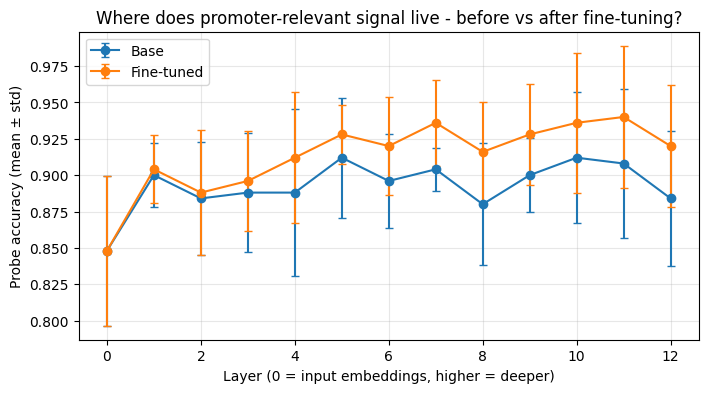

In [40]:
# One linear probe per layer per condition, scored with 5-fold stratified cross-validation
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

probe_results = {}
for condition, layers in probe_embeddings.items():
    means, stds = [], []
    for embeddings in layers:
        scores = cross_val_score(
            LogisticRegression(max_iter=1000),
            embeddings,
            probe_labels,
            cv=cv,
            scoring="accuracy",
        )
        means.append(scores.mean())
        stds.append(scores.std())
    probe_results[condition] = (np.array(means), np.array(stds))

print(f"{'Layer':>16} | {'Base':>13} | {'Fine-tuned':>13}")
for i in range(n_layers):
    name = "Input embeddings" if i == 0 else f"Layer {i}"
    base_m, base_s = probe_results["Base"][0][i], probe_results["Base"][1][i]
    ft_m, ft_s = probe_results["Fine-tuned"][0][i], probe_results["Fine-tuned"][1][i]
    print(f"{name:>16} | {base_m:>7.3f} ±{base_s:.3f} | {ft_m:>7.3f} ±{ft_s:.3f}")

plt.figure(figsize=(8, 4))
for condition, color in zip(["Base", "Fine-tuned"], ["tab:blue", "tab:orange"]):
    means, stds = probe_results[condition]
    plt.errorbar(range(n_layers), means, yerr=stds, fmt="o-", capsize=3,
                 color=color, label=condition)
plt.xlabel("Layer (0 = input embeddings, higher = deeper)")
plt.ylabel("Probe accuracy (mean ± std)")
plt.title("Where does promoter-relevant signal live - before vs after fine-tuning?")
#plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


- **The base curve is already well above chance (0.5)** — genome pre-training packed promoter-relevant information into the features, even though the model never saw a promoter label.
- **For the base model, accuracy peaks mid-network then dips toward layer 12** : the deepest layers specialize in the masked 6-mer objective, not in summarizing the whole sequence. The last layer is not automatically the most informative.
- **The fine-tuned curve lifts and flattens across the depth** — fine-tuning did not just sharpen the layer feeding the head: it pushed task information into *every* layer


[Further reading](https://arxiv.org/pdf/2512.00376) on probing andhow it can be used

## In Silico Saturated Mutagenesis

In the wet lab, researchers perform knockout experiments or saturated mutagenesis to determine which specific nucleotides are essential for a biological function.

We can recreate this digitally. By systematically mutating every position in a sequence window and plotting the drop in the model's confidence, we can force the model to reveal the sequence motifs it considers most critical.


In [43]:
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Helper functions (included here so the cell is self-contained)
def seq2kmer(seq, k=6):
    return " ".join([seq[i:i+k] for i in range(len(seq) - k + 1)])

def get_promoter_probability(seq):
    """takes a sequence and returns the predicted probability of it being a promoter"""
    kmer_seq = seq2kmer(seq)
    inputs = tokenizer(kmer_seq, return_tensors="pt", truncation=True, max_length=300)
    with torch.no_grad():
        device = loaded_promoter_model.device
        inputs = {k: v.to(device) for k, v in inputs.items()}
        logits = loaded_promoter_model(**inputs).logits
    probs = F.softmax(logits, dim=-1)
    return probs[0][1].item()

# Helper to aggressively scramble a DNA block (Swap A<->C, T<->G)
def scramble_block(block):
    mapping = {'A': 'C', 'C': 'A', 'T': 'G', 'G': 'T'}
    return "".join([mapping.get(base, base) for base in block])


In [44]:
SEQ_INDEX = 5
original_sequence = promoter_dataset["test"][SEQ_INDEX]["text"]
true_label = promoter_dataset["test"][SEQ_INDEX]["label"]

print(f"Analyzing Sequence Index {SEQ_INDEX} (True Label: {true_label})")
initial_confidence = get_promoter_probability(original_sequence)
print(f"Initial Model Confidence: {initial_confidence:.4f}")

Analyzing Sequence Index 5 (True Label: 1)
Initial Model Confidence: 0.9971


The following cell takes ~4min to run

In [45]:
%%time
# 2. In Silico Block Knockout (Sliding 5-bp disruptive window)
window_size = 5
probabilities = []
positions = list(range(len(original_sequence) - window_size))


for pos in positions:
    # Extract the block and scramble it
    target_block = original_sequence[pos : pos + window_size]
    scrambled_block = scramble_block(target_block)

    # Reconstructing the mutated sequence
    mutated_seq = original_sequence[:pos] + scrambled_block + original_sequence[pos + window_size:]

    # Measure the new probability
    probabilities.append(get_promoter_probability(mutated_seq))


CPU times: user 3min 37s, sys: 326 ms, total: 3min 37s
Wall time: 3min 56s


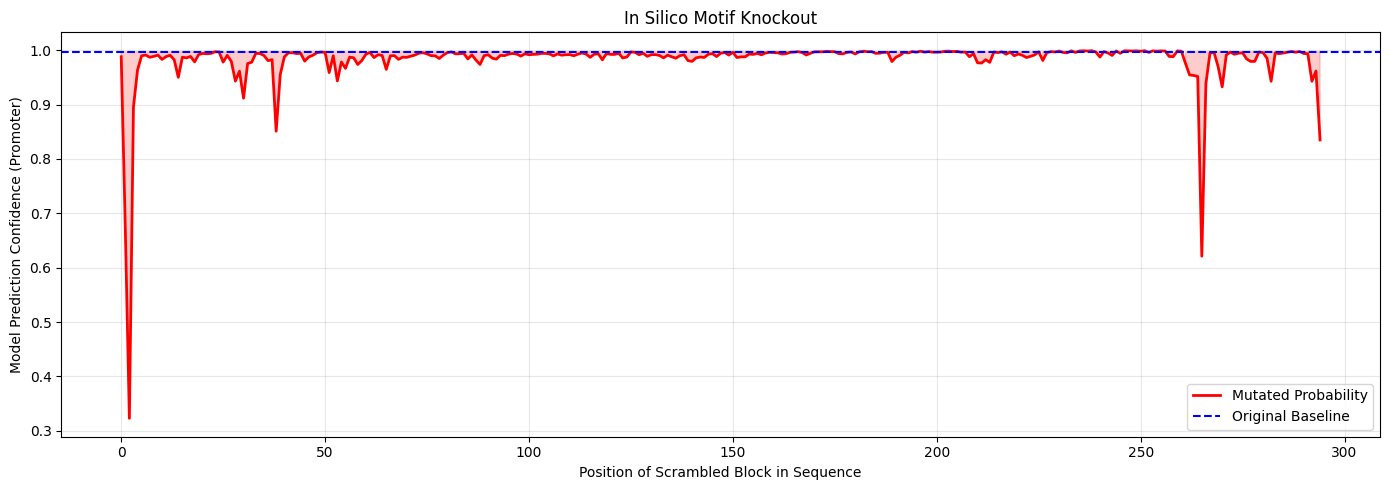

In [46]:
# Plotting the Knockout Sensitivity
plt.figure(figsize=(14, 5))
plt.plot(positions, probabilities, label="Mutated Probability", color="red", linewidth=2)
plt.axhline(y=initial_confidence, color='blue', linestyle='--', label="Original Baseline")

plt.fill_between(positions, probabilities, initial_confidence,
                 where=(np.array(probabilities) < initial_confidence),
                 color='red', alpha=0.2)

plt.title(f"In Silico Motif Knockout")
plt.xlabel("Position of Scrambled Block in Sequence")
plt.ylabel("Model Prediction Confidence (Promoter)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Annex: Designing Your Own Classification Head

By default, `AutoModelForSequenceClassificationfrom_pretrained(MODEL_NAME, num_labels=2)` provides a basic classifier which is made from a single linear layer.

It can be rebuilt to suit you needs:

- different number of classes, or a single logit for regression
- a deeper decoder for harder decision boundaries
- a multi-task model: one trunk feeding several heads

> You can even give a classifier which you trained already (typically on the embedding of the base model) so your classifier does not start with random weights.

In [47]:
# Anatomy of the default head that from_pretrained() built
print(loaded_promoter_model.classifier)

total_params = sum(p.numel() for p in loaded_promoter_model.parameters())
head_params = sum(p.numel() for n, p in loaded_promoter_model.named_parameters()
                  if n.startswith("classifier"))
print(f"\nHead: {head_params:,} params ({100 * head_params / total_params:.1f}% of the model)")
print(f"Trunk (+ pooler): {total_params - head_params:,} params")

Linear(in_features=768, out_features=2, bias=True)

Head: 1,538 params (0.0% of the model)
Trunk (+ pooler): 89,190,912 params


In [48]:
# Build a deeper custom head: same (batch, hidden_size) input as the stock head -> drop-in
import torch.nn as nn

class DeepPromoterHead(nn.Module):
    def __init__(self, hidden_size, hidden_dim=256, num_labels=2, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden_size, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_labels),
        )

    def forward(self, pooled_output):
        return self.net(pooled_output)

# Fresh backbone (pre-trained weights) + our head instead of the stock one
custom_head_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2
)
custom_head_model.classifier = DeepPromoterHead(hidden_size=custom_head_model.config.hidden_size)
print(custom_head_model.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: zhihan1996/DNA_bert_6
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DeepPromoterHead(
  (net): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=256, out_features=2, bias=True)
  )
)


In the interest of time, we are just going to train on 50 samples

In [49]:


# Smoke train: 50 steps (seconds, not a full epoch) just to prove the pipeline runs
smoke_args = TrainingArguments(
    output_dir="./head_test",
    per_device_train_batch_size=32,
    learning_rate=2e-5,
    max_steps=50,                    ## limit the number of samples
    logging_steps=10,
    weight_decay=0.01,
)

smoke_trainer = Trainer(
    model=custom_head_model,
    args=smoke_args,
    train_dataset=train_promoter,
)
smoke_trainer.train()

# NOTE: the head starts from random weights - fine-tuning recovers quickly.

Step,Training Loss
10,0.690709
20,0.683873
30,0.665366
40,0.661247
50,0.658453


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=50, training_loss=0.6719297790527343, metrics={'train_runtime': 126.1142, 'train_samples_per_second': 12.687, 'train_steps_per_second': 0.396, 'total_flos': 247230633600000.0, 'train_loss': 0.6719297790527343, 'epoch': 0.2})

## Annex: Freezing Layers of the Model

Full fine-tuning updates all ~90M parameters — but nothing forces that all-or-nothing choice. Every parameter carries a `requires_grad` flag, so any subset of layers can be turned into frozen machinery: no gradients computed, no optimizer states stored, no updates applied.

Freezing buys two things:

- **Memory**: each frozen parameter saves ~12 bytes (gradients + the two AdamW states never allocated) — the batch-size probe above measured the price of *full* fine-tuning; freezing is the other lever
- **Protection**: pre-trained features cannot be overwritten by a small or noisy task dataset — the classic guard against catastrophic forgetting


It is actually a good practice to **start with the backbone frozen and optimize the head only for a few epoch** (because the head starts with random weights),
and then unfreeze the rest of the model to proceed with further training.

In [54]:
# Every parameter is addressable by name - freezing is just selecting a subset
names = [name for name, _ in promoter_model.named_parameters()]
print(f"Parameter tensors: {len(names)}")
for name in names[:10] :
    print(" ", name)

print('...')
for name in names[-5:] :
    print(" ", name)


Parameter tensors: 201
  bert.embeddings.word_embeddings.weight
  bert.embeddings.position_embeddings.weight
  bert.embeddings.token_type_embeddings.weight
  bert.embeddings.LayerNorm.weight
  bert.embeddings.LayerNorm.bias
  bert.encoder.layer.0.attention.self.query.weight
  bert.encoder.layer.0.attention.self.query.bias
  bert.encoder.layer.0.attention.self.key.weight
  bert.encoder.layer.0.attention.self.key.bias
  bert.encoder.layer.0.attention.self.value.weight
...
  bert.encoder.layer.11.output.LayerNorm.bias
  bert.pooler.dense.weight
  bert.pooler.dense.bias
  classifier.weight
  classifier.bias


In [50]:

def report_trainability(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    print(f"trainable: {trainable:,} | frozen: {frozen:,}")

report_trainability(promoter_model)

Parameter tensors: 201
  bert.embeddings.word_embeddings.weight
  bert.embeddings.position_embeddings.weight
  bert.encoder.layer.5.attention.self.query.weight
  classifier.dense.weight
trainable: 89,192,450 | frozen: 0


In [55]:
frozen_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

# freezing the whole backbone (frozen_model.bert)
frozen_model.bert.requires_grad_(False)
report_trainability(frozen_model)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: zhihan1996/DNA_bert_6
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable: 1,538 | frozen: 89,190,912


In [56]:
# Freeze the input embeddings + the lowest transformer layers;
# train only the top of the stack and the classification head
N_FROZEN_LAYERS = 8

frozen_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

# freezing the whole backbone (frozen_model.bert)
frozen_model.bert.embeddings.requires_grad_(False)
report_trainability(frozen_model)


for i, layer in enumerate(frozen_model.bert.encoder.layer):
    layer.requires_grad_(i >= N_FROZEN_LAYERS)

print("Frozen layers 0-7 + embeddings, trainable:")
report_trainability(frozen_model)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: zhihan1996/DNA_bert_6
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable: 85,646,594 | frozen: 3,545,856
Frozen layers 0-7 + embeddings, trainable:
trainable: 28,943,618 | frozen: 60,248,832


In [57]:

# The Trainer automatically builds its optimizer from requires_grad=True parameters only
freeze_args = TrainingArguments(
    output_dir="./freeze_test",
    per_device_train_batch_size=32,
    learning_rate=2e-5,
    max_steps=50,
    logging_steps=10,
    weight_decay=0.01,
)

freeze_trainer = Trainer(
    model=frozen_model,
    args=freeze_args,
    train_dataset=train_promoter,
)
freeze_trainer.train()

Step,Training Loss
10,0.684394
20,0.652688
30,0.613879
40,0.596879
50,0.602136


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=50, training_loss=0.629995584487915, metrics={'train_runtime': 55.7561, 'train_samples_per_second': 28.696, 'train_steps_per_second': 0.897, 'total_flos': 246666614400000.0, 'train_loss': 0.629995584487915, 'epoch': 0.2})


- **Frozen trunk, head only**: extend the freeze to the remaining layers and the pooler
- **Progressive unfreezing**: start heavily frozen, unfreeze a few more layers every epoch. This is a standard recipe for adapting to small or out-of-distribution data, cheap to approximate as a few chained runs.
